In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, log_loss
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalMaxPooling1D, Flatten
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Input, Dropout, Flatten
from tensorflow.keras.layers import Attention, Concatenate, Multiply
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight
#from imblearn.over_sampling import SMOTE

# data shtuff

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
video = pd.read_csv(r"complete_video_clean_matchingrows.csv")
audio = pd.read_csv(r"complete_audio_clean_matchingrows.csv")

In [3]:
# copy of video and audio
video_df = video.copy()
audio_df = audio.copy()

In [4]:
video_features = video_df.drop(columns=['Target'])
video_target = video_df['Target']

audio_features = audio_df.drop(columns=['Target'])
audio_target = audio_df['Target']

In [5]:
# Initialize MinMaxScaler
scaler_video = MinMaxScaler()
scaler_audio = MinMaxScaler()

# Apply MinMaxScaler to the features
video_features_scaled = scaler_video.fit_transform(video_features)
audio_features_scaled = scaler_audio.fit_transform(audio_features)

In [ ]:
# Truncate both datasets to the same length to ensure alignment
video_features_scaled = video_features_scaled[:min_length]
video_target = video_target[:min_length]

audio_features_scaled = audio_features_scaled[:min_length]
audio_target = audio_target[:min_length]

print(video_target.shape)
print(audio_target.shape)

In [6]:
print(len(video_target))
print(len(audio_target))

568345
568345


In [7]:
# Verify that targets match after truncation
assert np.array_equal(video_target, audio_target), "Targets for video and audio do not match after truncation!"

In [8]:
# Recombine the scaled features with the target
video_df_scaled = np.hstack((video_features_scaled, video_target.values.reshape(-1, 1)))
audio_df_scaled = np.hstack((audio_features_scaled, audio_target.values.reshape(-1, 1)))

In [9]:
# Reshape video and audio data for LSTM (assuming a sequence length of 30 for both)
sequence_length_video = 30
sequence_length_audio = 30

num_features_video = video_features_scaled.shape[1]
num_features_audio = audio_features_scaled.shape[1]

In [10]:
# Reshaping the video data
X_video = video_features_scaled[:(len(video_features_scaled)//sequence_length_video)*sequence_length_video]
X_video = X_video.reshape(-1, sequence_length_video, num_features_video)
y_video = video_target.values[:(len(video_target)//sequence_length_video)*sequence_length_video]
y_video = y_video.reshape(-1, sequence_length_video)[:, 0]

# Reshaping the audio data
X_audio = audio_features_scaled[:(len(audio_features_scaled)//sequence_length_audio)*sequence_length_audio]
X_audio = X_audio.reshape(-1, sequence_length_audio, num_features_audio)
y_audio = audio_target.values[:(len(audio_target)//sequence_length_audio)*sequence_length_audio]
y_audio = y_audio.reshape(-1, sequence_length_audio)[:, 0]

In [11]:
# Ensure the target shape matches
assert np.array_equal(y_video, y_audio), "Targets for video and audio do not match!"

# Evaluation

In [24]:
# Evaluate Model
def evaluate_model(y_true, y_pred, model_name):
    print(f"Evaluation for {model_name}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("Classification Report:")
    print(classification_report(y_true, y_pred))
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:", recall_score(y_true, y_pred))
    print("F1 Score:", f1_score(y_true, y_pred))
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp)
    print("Specificity:", specificity)
    print("ROC-AUC:", roc_auc_score(y_true, y_pred))

In [25]:
# Plot Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix for {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [34]:
# Plotting the training and validation accuracy and loss
def plot_training_history(history, model_name):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))
    #plt.rcParams.update({'font.size': 16})
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title(f'Model Accuracy for {model_name}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='lower right')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title(f'Model Loss for {model_name}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper right')

    plt.tight_layout()
    plt.show()

In [27]:
# Plot Precision-Recall Curve
def plot_roc_recall(model, X_test, y_test, model_name):
    # Plot ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, model.predict(X_test))
    plt.plot(fpr, tpr, color='blue', lw=2, label='ROC curve')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve for {model_name}')
    plt.legend(loc='lower right')
    plt.show()

    # Plot precision-recall curve
    precision, recall, thresholds = precision_recall_curve(y_test, model.predict(X_test))
    plt.plot(recall, precision, color='blue', lw=2, label='Precision-Recall curve')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall Curve for {model_name}')
    plt.legend(loc='lower left')
    plt.show()

# model

In [12]:
def build_bilstm_attention_branch(input_shape):
    input_layer = Input(shape=input_shape)

    # BiLSTM Layer
    bilstm = Bidirectional(LSTM(64, return_sequences=True))(input_layer)

    # Attention Layer
    attention = Attention()([bilstm, bilstm])

    # Concatenate BiLSTM output with Attention output
    combined = Concatenate()([bilstm, attention])

    # Apply GlobalMaxPooling1D to reduce sequence dimension
    pooling = GlobalMaxPooling1D()(combined)

    return input_layer, pooling

In [13]:
# Define input shapes for both modalities
video_input_shape = (sequence_length_video, num_features_video)
audio_input_shape = (sequence_length_audio, num_features_audio)

In [14]:
# Build video branch
video_input, video_branch_output = build_bilstm_attention_branch(video_input_shape)

In [15]:
# Build audio branch
audio_input, audio_branch_output = build_bilstm_attention_branch(audio_input_shape)

In [16]:
# Concatenate the outputs from both branches
merged = Concatenate()([video_branch_output, audio_branch_output])

In [17]:
# Dense layers after concatenation
dense = Dense(128, activation='relu')(merged)
dropout = Dropout(0.5)(dense)

In [18]:
# Output layer for binary classification
output_layer = Dense(1, activation='sigmoid')(dropout)

In [19]:
# Define the multimodal model
multimodal_model = Model(inputs=[video_input, audio_input], outputs=output_layer)
multimodal_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [20]:
# Summary of the model
multimodal_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 378)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 30, 78)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 30, 128)   │    226,816 │ input_layer[0][0] │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 30, 128)   │     73,216 │ input_layer_1[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 30, 128)   │          0 │ bidirectional[0]… │
│ (Attention)         │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_1         │ (None, 30, 128)   │          0 │ bidirectional_1[… │
│ (Attention)         │                   │            │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 30, 256)   │          0 │ bidirectional[0]… │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 30, 256)   │          0 │ bidirectional_1[… │
│ (Concatenate)       │                   │            │ attention_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 256)       │          0 │ concatenate[0][0] │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 256)       │          0 │ concatenate_1[0]… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 512)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     65,664 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │        129 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 365,825 (1.40 MB)

 Trainable params: 365,825 (1.40 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
X_train_video, X_test_video, y_train, y_test = train_test_split(X_video, y_video, test_size=0.2, random_state=42)
X_train_audio, X_test_audio, _, _ = train_test_split(X_audio, y_audio, test_size=0.2, random_state=42)

In [22]:
# Train the model
history = multimodal_model.fit(
    [X_train_video, X_train_audio], y_train,
    epochs=10, batch_size=32,
    validation_data=([X_test_video, X_test_audio], y_test)
)

Epoch 1/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 63s 96ms/step - accuracy: 0.6897 - loss: 0.6116 - val_accuracy: 0.7237 - val_loss: 0.5784
Epoch 2/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 55s 116ms/step - accuracy: 0.7384 - loss: 0.5167 - val_accuracy: 0.7493 - val_loss: 0.4995
Epoch 3/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 71s 150ms/step - accuracy: 0.7764 - loss: 0.4584 - val_accuracy: 0.7944 - val_loss: 0.4253
Epoch 4/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 65s 136ms/step - accuracy: 0.8174 - loss: 0.3939 - val_accuracy: 0.8221 - val_loss: 0.3612
Epoch 5/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 78s 127ms/step - accuracy: 0.8672 - loss: 0.3091 - val_accuracy: 0.8696 - val_loss: 0.2957
Epoch 6/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 56s 117ms/step - accuracy: 0.8892 - loss: 0.2658 - val_accuracy: 0.9248 - val_loss: 0.2077
Epoch 7/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 55s 117ms/step - accuracy: 0.9126 - loss: 0.2138 - val_accuracy: 0.9274 - val_loss: 0.1902
Epoch 8/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 53s 112ms/step - accuracy: 0.9294 - loss: 0.

In [28]:
# Predict on the test data
y_pred_probs = multimodal_model.predict([X_test_video, X_test_audio])
y_pred = (y_pred_probs > 0.5).astype(int)

119/119 ━━━━━━━━━━━━━━━━━━━━ 9s 62ms/step


In [ ]:
from tensorflow.keras.models import save_model

# Save the trained model to a file
model_path = "multimodal_bilstm_attention_model_own_split.h5"
multimodal_model.save(model_path)
print(f"Model saved to {model_path}")

In [ ]:
import pickle

# Assuming `history` is the variable containing your training history
history_path = "training_history_own_split.pkl"

# Save the history
with open(history_path, 'wb') as file:
    pickle.dump(history.history, file)

print(f"Training history saved to {history_path}")

# results

In [29]:
# Evaluate the model
evaluate_model(y_test, y_pred, "Multimodal BiLSTM + Attention Model")

Evaluation for Multimodal BiLSTM + Attention Model
Confusion Matrix:
[[2430  182]
 [  65 1112]]
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.93      0.95      2612
           1       0.86      0.94      0.90      1177

    accuracy                           0.93      3789
   macro avg       0.92      0.94      0.93      3789
weighted avg       0.94      0.93      0.94      3789

Accuracy: 0.9348112958564265
Precision: 0.8593508500772797
Recall: 0.9447748513169074
F1 Score: 0.9000404694455686
Specificity: 0.9303215926493109
ROC-AUC: 0.9375482219831092


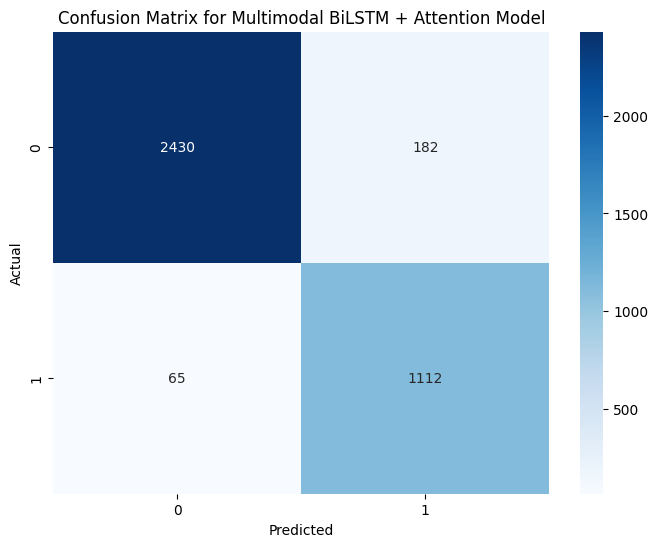

In [30]:
plot_confusion_matrix(y_test, y_pred, "Multimodal BiLSTM + Attention Model")

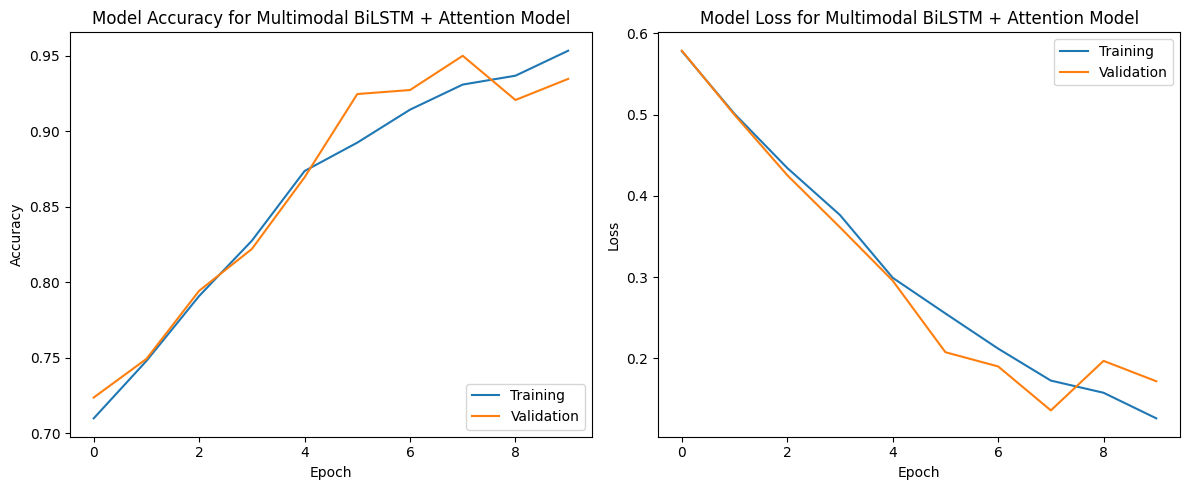

In [35]:
plot_training_history(history, "Multimodal BiLSTM + Attention Model")

119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step


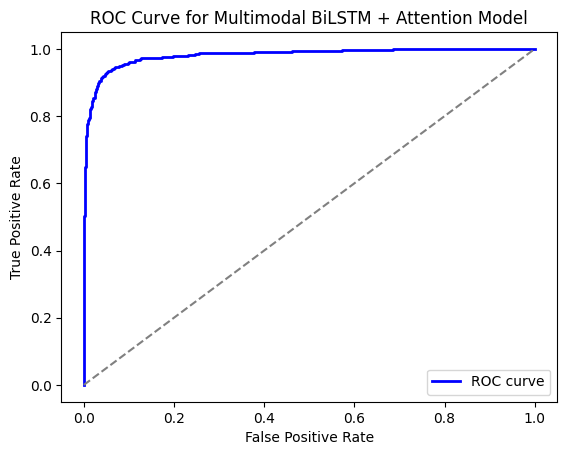

119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step


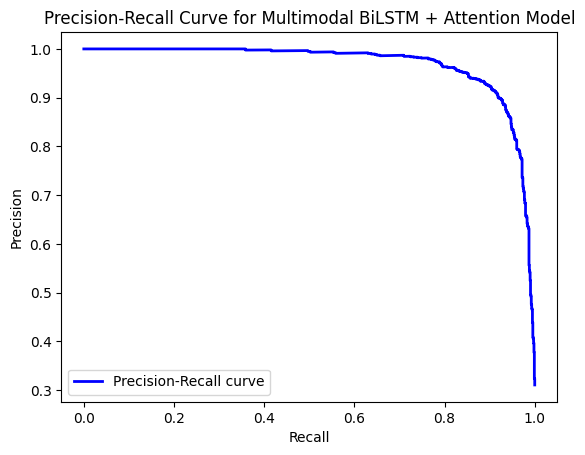

In [36]:
plot_roc_recall(multimodal_model, [X_test_video, X_test_audio], y_test, "Multimodal BiLSTM + Attention Model")